# Implementación técnica para el acompañamiento académico en matemáticas
**Guía 3.1.2**

Integrantes: Genesis Baeza, Jimena Galicia, Alejandra González, Constanza González y Diego Villar.

Asignatura: Gestión de Proyectos de Datos. 

Profesor: Ronald Villalobos Arrano. Sección 002D.

Este cuaderno desarrolla las ocho tareas de la guía y la reflexión grupal. El objetivo es estimar una señal de bajo rendimiento en **matemáticas** para apoyar la revisión docente.

Se usa exclusivamente la **versión 1 de Kaggle** de `neuralsorcerer/student-performance`. La fuente declara que los datos son **sintéticos**. Los resultados no demuestran eficacia en estudiantes reales, equidad institucional ni impacto de una intervención. El piloto de aproximadamente 1.500 estudiantes descrito en los informes es un contexto propuesto; estos millones de registros no pertenecen a ese colegio.

**Definición provisional:** clase 1 si `TestScore_Math < 60`, clase 0 en otro caso. El corte 60/100 permite desarrollar el ejercicio, pero no está fijado en las evaluaciones ni equivale automáticamente a reprobación en Chile. Debe ser validado por el docente/UTP. Se fija antes de entrenar y no se elige por los resultados de test.

**Límite temporal:** no hay fechas de medición ni resultados futuros identificados. Se excluyen las notas contemporáneas de las entradas, pero no se puede demostrar que asistencia o hábitos se midieron antes de matemáticas. Se trata de un prototipo de asociación y clasificación; para llamarlo alerta temprana validada se requieren datos longitudinales.

El modo predeterminado utiliza muestras uniformes reproducibles de **300.000 filas de train, 150.000 de validación y 150.000 de test**, tomadas recorriendo todos los archivos. No utiliza simplemente las primeras filas. Los conteos y controles estructurales recorren los archivos completos; entrenamiento, gráficos y métricas usan las muestras indicadas. Aumentar estos tamaños implica ejecutar nuevamente todo el flujo y no seleccionar el tamaño mirando resultados de test.

### Cómo se incorporan las evaluaciones previas
| Documento o requisito | Aplicación en el cuaderno |
|---|---|
| Evaluación 1 y RF-01 | Clasificación de bajo rendimiento en matemáticas y revisión humana |
| RF-03 | Auditoría de errores por género, etnia y cuartil socioeconómico, exportada por separado |
| RF-02 | CSV con probabilidades y niveles para una futura conexión a Power BI; no se entrega un dashboard terminado |
| RNF-05 y H3 | Semilla, versión de datos, huellas, versiones de software, pipeline y ficha de modelo |
| CRISP-DM | Comprensión del problema, datos, preparación, modelado, evaluación y prototipo de despliegue |
| Automatización por lotes | Inferencia y exportación con bitácora; sin envío automático de mensajes |
| H4 y RNF-02 | La aprobación ética, cifrado y control de accesos de producción siguen pendientes; este notebook no acredita su implementación |

**Corrección del diccionario:** Kaggle define `StudyHours` como horas de estudio **por día** (0–4). La evaluación 1 las describe como semanales. Aquí se utiliza la definición de la fuente, sin multiplicar ni dividir los valores originales.

In [1]:
import importlib.util, subprocess, sys
for modulo, paquete in [('numpy','numpy'),('pandas','pandas'),('matplotlib','matplotlib'),('sklearn','scikit-learn'),('joblib','joblib')]:
    if importlib.util.find_spec(modulo) is None:
        subprocess.check_call([sys.executable,'-m','pip','install','-q',paquete])
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json, hashlib, platform, time, gc
from datetime import datetime, timezone
import sklearn, joblib
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
    roc_auc_score, average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
    RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance
SEED=42
CORTE_MATH=60.0
HANDLE='neuralsorcerer/student-performance/versions/1'
TAMANOS={'train':300_000,'validation':150_000,'test':150_000}
OUT=Path('salidas_matematicas'); OUT.mkdir(exist_ok=True)
versiones={'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'sklearn':sklearn.__version__}
print('Versiones:',versiones)
print('Configuración:',HANDLE,TAMANOS,'Corte matemáticas:',CORTE_MATH)

Versiones: {'python': '3.12.14', 'numpy': '2.3.5', 'pandas': '2.2.3', 'sklearn': '1.8.0'}
Configuración: neuralsorcerer/student-performance/versions/1 {'train': 300000, 'validation': 150000, 'test': 150000} Corte matemáticas: 60.0


## 1 Cargar el dataset del proyecto
Los archivos se descargan con `dataset_download`, usando un identificador de versión fijo. Así se puede leer cada CSV con `pandas.read_csv(..., chunksize=...)`, sin construir un DataFrame de ocho millones de filas.

El código compartido por Kaggle necesita un nombre de archivo: `file_path = "train.csv"`, por ejemplo. Un nombre vacío no identifica qué archivo cargar. En este cuaderno se utiliza descarga más lectura por bloques para controlar la memoria.

Si ya descargaste los tres CSV de la versión 1, puedes ubicarlos en `datos_kaggle/`. La celda comprueba sus tamaños esperados y columnas; si la descarga exige autenticación, usa `kagglehub.login()` en una celda privada de Colab y vuelve a ejecutar. No escribas credenciales en el cuaderno entregable.

In [2]:
ESPERADOS={'train':1_328_598_306,'validation':165_931_109,'test':166_057_940}
local=Path('datos_kaggle')
if all((local/f'{s}.csv').exists() for s in TAMANOS):
    base=local
    print('Se usan los CSV locales de datos_kaggle/.')
else:
    if importlib.util.find_spec('kagglehub') is None:
        subprocess.check_call([sys.executable,'-m','pip','install','-q','kagglehub'])
    import kagglehub
    base=Path(kagglehub.dataset_download(HANDLE))
    print('Descarga de la versión 1 completada.')
rutas={s:base/f'{s}.csv' for s in TAMANOS}
COLUMNAS=['Age','Grade','Gender','Race','SES_Quartile','ParentalEducation','SchoolType','Locale',
 'TestScore_Math','TestScore_Reading','TestScore_Science','GPA','AttendanceRate','StudyHours',
 'InternetAccess','Extracurricular','PartTimeJob','ParentSupport','Romantic','FreeTime','GoOut']
for s,p in rutas.items():
    if p.stat().st_size != ESPERADOS[s]:
        raise ValueError(f'{s}: tamaño diferente al archivo original de la versión 1. Revisar procedencia; no mezclar versiones.')
    if list(pd.read_csv(p,nrows=0).columns) != COLUMNAS:
        raise ValueError(f'{s}: esquema incompatible con la versión usada en el proyecto.')
print('Los tres archivos coinciden con los tamaños y el esquema esperado de Kaggle v1.')

Se usan los CSV locales de datos_kaggle/.
Los tres archivos coinciden con los tamaños y el esquema esperado de Kaggle v1.


### Lectura por bloques y muestreo uniforme
A cada fila se le asigna una prioridad aleatoria con semilla fija. Se conservan las k menores entre todos los bloques: todas las filas del archivo tienen la misma probabilidad de inclusión. Los atributos de texto se leen como texto para que el hash de filas sea comparable entre archivos; los decimales mantienen precisión float64.

Se calculan conteos de nulos y huellas SHA-256 de los archivos completos para trazabilidad. Se conservan hashes de fila de 64 bits para buscar duplicados y coincidencias entre particiones: son un control práctico, no una identificación de estudiantes ni una prueba criptográfica de identidad. Si aparecen coincidencias, el proceso se detiene para revisarlas en vez de eliminarlas silenciosamente.

In [3]:
def sha256_archivo(ruta):
    h=hashlib.sha256()
    with open(ruta,'rb') as f:
        for bloque in iter(lambda:f.read(8*1024*1024),b''): h.update(bloque)
    return h.hexdigest()
TEXTO={c:'string' for c in ['Gender','Race','ParentalEducation','SchoolType','Locale']}
DECIMALES={c:'float64' for c in ['TestScore_Math','TestScore_Reading','TestScore_Science','GPA','AttendanceRate','StudyHours']}
def leer_muestra(ruta,k,seed):
    rng=np.random.default_rng(seed); muestra=None; hashes=[]; total=0
    nulos=pd.Series(0,index=COLUMNAS,dtype='int64')
    for bloque in pd.read_csv(ruta,chunksize=100_000,dtype={**TEXTO,**DECIMALES}):
        nulos+=bloque.isna().sum()
        hashes.append(pd.util.hash_pandas_object(bloque,index=False).to_numpy())
        bloque['_fila_fuente']=np.arange(total,total+len(bloque))+2
        total+=len(bloque)
        bloque['_prioridad']=rng.random(len(bloque))
        candidato=bloque if muestra is None else pd.concat([muestra,bloque],ignore_index=True)
        muestra=candidato.nsmallest(k,'_prioridad')
    h=np.concatenate(hashes); unicos=np.unique(h)
    reporte={'filas_originales':total,'filas_muestra':len(muestra),'nulos_originales':int(nulos.sum()),
             'hashes_repetidos':int(len(h)-len(unicos)),'sha256':sha256_archivo(ruta)}
    return muestra.drop(columns='_prioridad').reset_index(drop=True),unicos,reporte
muestras={}; hashes={}; calidad={}
for i,s in enumerate(TAMANOS):
    muestras[s],hashes[s],calidad[s]=leer_muestra(rutas[s],TAMANOS[s],SEED+i)
    print(s,calidad[s])
print('\nControl de coincidencias entre archivos completos')
for a,b in [('train','validation'),('train','test'),('validation','test')]:
    n=len(np.intersect1d(hashes[a],hashes[b],assume_unique=True))
    print(a,b,n)
    if n: raise ValueError('Hay coincidencias de hash entre particiones: revisar registros antes de entrenar.')
if any(v['hashes_repetidos'] for v in calidad.values()):
    raise ValueError('Revisar los posibles duplicados de origen antes de entrenar.')
del hashes; gc.collect()
pd.DataFrame(calidad).T.to_csv(OUT/'calidad_y_procedencia.csv')
print('\nPrimeras filas de la muestra train:\n',muestras['train'].head().to_string(index=False))

train {'filas_originales': 8000774, 'filas_muestra': 300000, 'nulos_originales': 0, 'hashes_repetidos': 0, 'sha256': '5eb46ab71ca8bf9d80962a6ffc9fe20593fd301a6eaef8b4cf9aa64663648fb3'}
validation {'filas_originales': 999229, 'filas_muestra': 150000, 'nulos_originales': 0, 'hashes_repetidos': 0, 'sha256': 'afee5b88a598ad7e3fc22e7023d2c0e9ace252c25ffd1fcca854293afab8e647'}
test {'filas_originales': 999997, 'filas_muestra': 150000, 'nulos_originales': 0, 'hashes_repetidos': 0, 'sha256': '076e1f68d4a39e95a81ca43f05255dda3e73fc791d2af6e169f32825aa08fe95'}

Control de coincidencias entre archivos completos
train validation 0
train test 0
validation test 0

Primeras filas de la muestra train:
  Age  Grade Gender        Race  SES_Quartile ParentalEducation SchoolType   Locale  TestScore_Math  TestScore_Reading  TestScore_Science      GPA  AttendanceRate  StudyHours  InternetAccess  Extracurricular  PartTimeJob  ParentSupport  Romantic  FreeTime  GoOut  _fila_fuente
  17     12   Male       Whi

## 2 Analizar las clases y generar gráficos representativos
El análisis exploratorio se realiza en train. La clase 1 significa **puntaje de matemáticas inferior al corte provisional**, no diagnóstico de incapacidad ni certeza de fracaso futuro. La distribución de clases de validación y test se describe cuando se usa cada conjunto, sin redefinir el corte para equilibrarlos.

Las relaciones entre asistencia, estudio y resultado sirven para describir la muestra. No permiten concluir que aumentar una variable cause una mejora en el rendimiento.

           Clase  Cantidad  Porcentaje
Sin bajo puntaje    280214        93.4
    Bajo puntaje     19786         6.6

Correlaciones descriptivas en train:
                 TestScore_Math  AttendanceRate  StudyHours
TestScore_Math           1.000           0.815       0.453
AttendanceRate           0.815           1.000       0.461
StudyHours               0.453           0.461       1.000


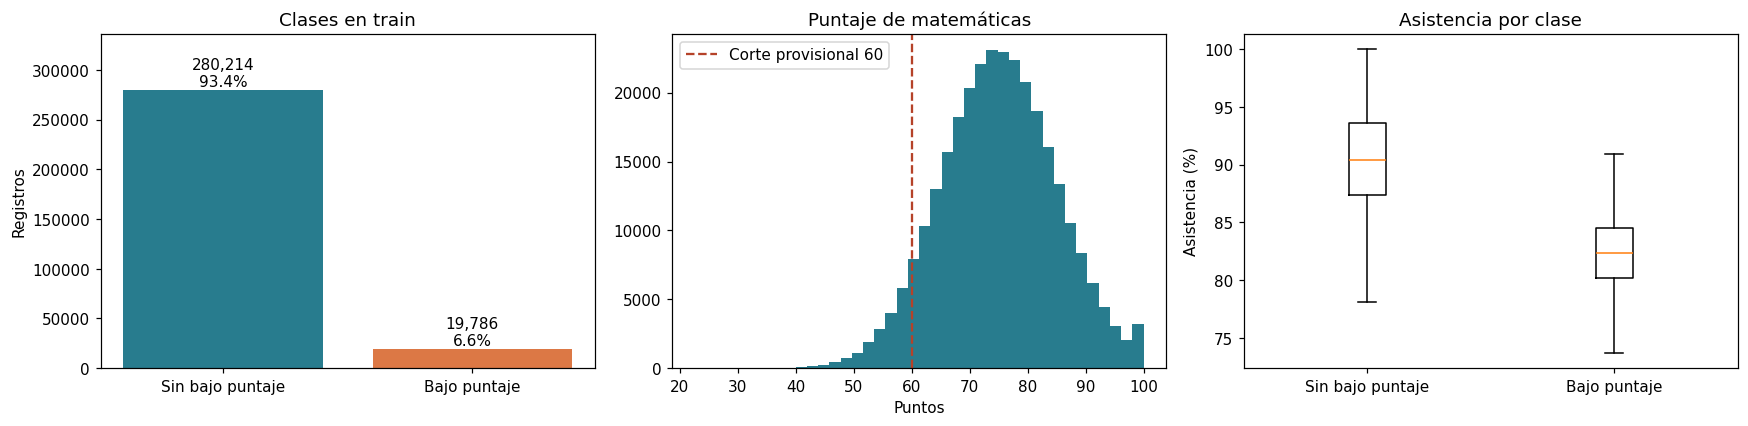

In [4]:
train=muestras['train']; valid=muestras['validation']; test=muestras['test']
def objetivo(datos):
    if datos.TestScore_Math.isna().any(): raise ValueError('No imputar la variable objetivo.')
    if not datos.TestScore_Math.between(0,100).all(): raise ValueError('Puntajes fuera de rango.')
    return (datos.TestScore_Math<CORTE_MATH).astype('int8')
y_train=objetivo(train)
conteo=y_train.value_counts().reindex([0,1],fill_value=0)
print(pd.DataFrame({'Clase':['Sin bajo puntaje','Bajo puntaje'],'Cantidad':conteo.values,'Porcentaje':conteo.values/len(train)*100}).round(2).to_string(index=False))
fig,ax=plt.subplots(1,3,figsize=(16,4))
ax[0].bar(['Sin bajo puntaje','Bajo puntaje'],conteo.values,color=['#287c8e','#dc7845'])
ax[0].set_title('Clases en train');ax[0].set_ylabel('Registros');ax[0].set_ylim(0,conteo.max()*1.2)
for i,n in enumerate(conteo):ax[0].text(i,n,f'{n:,}\n{n/len(train):.1%}',ha='center',va='bottom')
ax[1].hist(train.TestScore_Math,bins=40,color='#287c8e');ax[1].axvline(CORTE_MATH,color='#b54229',linestyle='--',label='Corte provisional 60')
ax[1].set_title('Puntaje de matemáticas');ax[1].set_xlabel('Puntos');ax[1].legend()
ax[2].boxplot([train.loc[y_train==c,'AttendanceRate'].to_numpy()*100 for c in [0,1]],showfliers=False)
ax[2].set_xticks([1,2],['Sin bajo puntaje','Bajo puntaje']);ax[2].set_ylabel('Asistencia (%)');ax[2].set_title('Asistencia por clase')
plt.tight_layout();plt.savefig(OUT/'clases_train.png',dpi=140);plt.show()
print('\nCorrelaciones descriptivas en train:\n',train[['TestScore_Math','AttendanceRate','StudyHours']].corr().round(3).to_string())

## 3 Preparar los datos y seleccionar variables
**Variable dependiente:** `RiesgoMatematicas = 1[TestScore_Math < 60]`.

| Variables | Decisión y motivo |
|---|---|
| AttendanceRate, StudyHours | Predictores de asistencia y hábitos, relevantes para acompañamiento; disponibilidad temporal por confirmar |
| Grade | Nivel escolar; Age se excluye por redundancia |
| InternetAccess, ParentSupport | Acceso y apoyo; posibles proxies que requieren auditoría |
| Extracurricular, PartTimeJob, FreeTime, GoOut | Contexto de actividades y tiempo; no deben usarse para responsabilizar al estudiante |
| TestScore_Math | Solo construye la clase; nunca entra al modelo |
| GPA, TestScore_Reading, TestScore_Science | Excluidas: no se conoce si contienen información posterior o del mismo periodo que el resultado |
| Gender, Race, SES_Quartile | Solo auditoría de equidad, separada de la predicción |
| Romantic, ParentalEducation, SchoolType, Locale | Excluidas del prototipo por minimización de datos |
| _fila_fuente | Solo trazabilidad técnica, no predictor ni identificador real de estudiante |

Las entradas seleccionadas son numéricas o binarias; no hace falta codificar texto. Se imputa con mediana aprendida **solo en train** dentro del pipeline. La regresión logística además estandariza con estadísticas de train. No se aplica sobremuestreo antes de separar conjuntos. No se confunde normalizar con dividir los datos.

La exclusión de atributos protegidos no garantiza equidad: asistencia o acceso a recursos pueden transportar información social. Por eso se conserva una auditoría separada por subgrupos.

In [5]:
FEATURES=['Grade','AttendanceRate','StudyHours','InternetAccess','Extracurricular','PartTimeJob','ParentSupport','FreeTime','GoOut']
AUDITORIA=['Gender','Race','SES_Quartile']
LIMITES={'Grade':(9,12),'AttendanceRate':(0.70,1),'StudyHours':(0,4),'FreeTime':(1,5),'GoOut':(1,5)}
BINARIAS=['InternetAccess','Extracurricular','PartTimeJob','ParentSupport']
def validar_entradas(datos):
    faltan=set(FEATURES)-set(datos.columns)
    if faltan: raise ValueError(f'Faltan columnas: {sorted(faltan)}')
    x=datos[FEATURES].apply(pd.to_numeric,errors='raise')
    if x.empty or x.isna().all(axis=1).any(): raise ValueError('Lote vacío o fila sin datos predictivos.')
    if np.isinf(x.to_numpy()).any(): raise ValueError('Valores infinitos.')
    for c,(lo,hi) in LIMITES.items():
        if not x[c].dropna().between(lo,hi).all(): raise ValueError(f'{c} fuera de rango {lo}–{hi}.')
    for c in BINARIAS:
        if not x[c].dropna().isin([0,1]).all(): raise ValueError(f'{c} debe ser 0 o 1.')
    for c in ['Grade','FreeTime','GoOut']:
        if not (x[c].dropna()%1==0).all(): raise ValueError(f'{c} debe ser entero.')
    return x
X_train=validar_entradas(train)
assert not set(FEATURES)&set(AUDITORIA+['GPA','TestScore_Math','TestScore_Reading','TestScore_Science'])
print('Predictores:',FEATURES)
print('Faltantes en predictores de train:',int(X_train.isna().sum().sum()))

Predictores: ['Grade', 'AttendanceRate', 'StudyHours', 'InternetAccess', 'Extracurricular', 'PartTimeJob', 'ParentSupport', 'FreeTime', 'GoOut']
Faltantes en predictores de train: 0


## 4 Separar los datos de entrenamiento validación y test
Se respetan los archivos de origen: no se concatenan para volver a dividir. El muestreo se hizo independientemente dentro de cada uno, sin compartir filas. Train ajusta parámetros y transformaciones; validación selecciona modelo y umbral; test mide el resultado una vez cerrada la selección.

**Antecedente que debe declararse:** test ya fue explorado en la evaluación 1 y utilizado en el cuaderno previo de GPA. No es un conjunto totalmente virgen para el equipo. Este nuevo experimento mantiene sus muestras fuera del entrenamiento, pero una validación externa futura aportaría una comprobación más fuerte. La versión actual no tiene identificadores de estudiante: no se puede auditar repetición de personas, solo coincidencias de registros.

In [6]:
X_val=validar_entradas(valid); y_val=objetivo(valid)
print(pd.DataFrame([{'Conjunto':s,'Filas originales':calidad[s]['filas_originales'],'Filas utilizadas':len(muestras[s])} for s in TAMANOS]).to_string(index=False))
print('Positivos train:',int(y_train.sum()),'| validación:',int(y_val.sum()))
assert y_train.nunique()==2 and y_val.nunique()==2

  Conjunto  Filas originales  Filas utilizadas
     train           8000774            300000
validation            999229            150000
      test            999997            150000
Positivos train: 19786 | validación: 9912


## 5 Entrenar modelos y analizar si la preparación fue suficiente
Se comparan una referencia mayoritaria, regresión logística e HistGradientBoosting (árboles de boosting). La referencia permite comprobar que la exactitud por sí sola puede ser engañosa con pocos casos positivos.

**Regla de selección fijada antes de test:** para cada candidato, buscar el umbral de probabilidad que maximiza F2 en validación en una grilla de 0,02 a 0,80. Luego elegir el candidato con mayor F2 de validación. F2 da más peso al recall que a la precisión, apropiado como propuesta inicial para acompañamiento. El costo de falsas alertas y la capacidad de atención todavía deben acordarse con UTP.

El corte del puntaje (60 puntos) y el umbral de probabilidad cumplen funciones distintas: uno define la respuesta real del ejercicio; el otro decide cuándo emitir una señal del modelo. No se ajustan mirando test. Se presenta una comparación acotada, no una búsqueda exhaustiva de hiperparámetros.

In [7]:
modelos={
 'Referencia mayoritaria':Pipeline([('imputar',SimpleImputer(strategy='median')),('modelo',DummyClassifier(strategy='most_frequent'))]),
 'Regresión logística':Pipeline([('imputar',SimpleImputer(strategy='median')),('escalar',StandardScaler()),('modelo',LogisticRegression(max_iter=500,random_state=SEED))]),
 'HistGradientBoosting':Pipeline([('imputar',SimpleImputer(strategy='median')),('modelo',HistGradientBoostingClassifier(max_iter=120,max_leaf_nodes=15,l2_regularization=1,early_stopping=False,random_state=SEED))])}
def medir(y,p,t):
    pr=(p>=t).astype(int)
    return {'Accuracy':accuracy_score(y,pr),'Precision':precision_score(y,pr,zero_division=0),
    'Recall':recall_score(y,pr,zero_division=0),'F1':f1_score(y,pr,zero_division=0),
    'F2':fbeta_score(y,pr,beta=2,zero_division=0),'ROC_AUC':roc_auc_score(y,p),'AP':average_precision_score(y,p)}
val_filas=[];umbrales={};probas_val={};ajustes=[]
for nombre,m in modelos.items():
    inicio=time.perf_counter();m.fit(X_train,y_train)
    p=m.predict_proba(X_val)[:,1];probas_val[nombre]=p
    ts=np.array([0.5]) if nombre=='Referencia mayoritaria' else np.round(np.arange(0.02,0.801,0.02),2)
    f2s=[fbeta_score(y_val,p>=t,beta=2,zero_division=0) for t in ts]
    t=float(ts[int(np.argmax(f2s))]);umbrales[nombre]=t
    for tt,ss in zip(ts,f2s):ajustes.append({'Modelo':nombre,'Umbral':tt,'F2_validacion':ss})
    val_filas.append({'Modelo':nombre,'Umbral':t,'Segundos':time.perf_counter()-inicio,**medir(y_val,p,t)})
val_metricas=pd.DataFrame(val_filas).set_index('Modelo')
elegido=val_metricas.drop(index='Referencia mayoritaria').F2.idxmax()
final=modelos[elegido];umbral=umbrales[elegido]
print(val_metricas.round(4).to_string())
print('\nElegido por validación:',elegido,'| umbral:',umbral)
f2_train=fbeta_score(y_train,final.predict_proba(X_train)[:,1]>=umbral,beta=2)
print('F2 train:',round(f2_train,4),'| F2 validación:',round(val_metricas.loc[elegido,'F2'],4))
val_metricas.to_csv(OUT/'metricas_validacion.csv');pd.DataFrame(ajustes).to_csv(OUT/'busqueda_umbrales.csv',index=False)

                        Umbral  Segundos  Accuracy  Precision  Recall      F1      F2  ROC_AUC      AP
Modelo                                                                                                
Referencia mayoritaria    0.50    0.3200    0.9339     0.0000   0.000  0.0000  0.0000   0.5000  0.0661
Regresión logística       0.12    0.8139    0.8964     0.3687   0.798  0.5044  0.6473   0.9405  0.5813
HistGradientBoosting      0.14    1.9577    0.8977     0.3717   0.794  0.5064  0.6470   0.9402  0.5787

Elegido por validación: Regresión logística | umbral: 0.12
F2 train: 0.6395 | F2 validación: 0.6473


### Revisión de la preparación y explicación de variables
El pipeline entrena sin la variable que revela la respuesta y sin atributos protegidos como entradas. La comparación de F2 entre train y validación permite observar una posible brecha de sobreajuste. Una brecha pequeña no prueba capacidad futura.

Para explicar el modelo se calcula importancia por permutación en una submuestra de validación: cuánto disminuye average precision al desordenar cada variable. No mide causalidad y las variables correlacionadas pueden repartirse importancia. No se eliminan variables ni se reentrena después de este análisis.

       Variable  Disminucion_AP  Desviacion
 AttendanceRate          0.4974      0.0023
     StudyHours          0.0213      0.0054
          Grade          0.0001      0.0001
          GoOut          0.0001      0.0000
       FreeTime          0.0001      0.0000
Extracurricular         -0.0001      0.0000
 InternetAccess         -0.0001      0.0002
    PartTimeJob         -0.0002      0.0001
  ParentSupport         -0.0005      0.0001


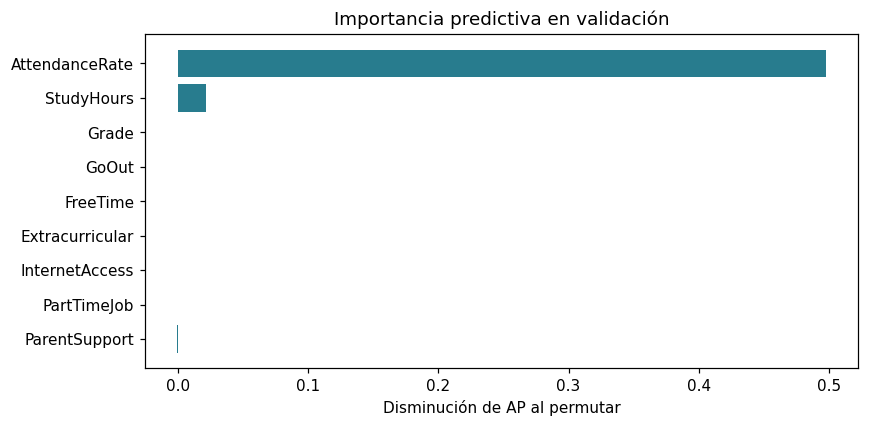

In [8]:
idx=np.random.default_rng(SEED).choice(len(X_val),size=min(10_000,len(X_val)),replace=False)
imp=permutation_importance(final,X_val.iloc[idx],y_val.iloc[idx],scoring='average_precision',n_repeats=3,random_state=SEED,n_jobs=1)
importancias=pd.DataFrame({'Variable':FEATURES,'Disminucion_AP':imp.importances_mean,'Desviacion':imp.importances_std}).sort_values('Disminucion_AP',ascending=False)
print(importancias.round(4).to_string(index=False))
importancias.to_csv(OUT/'importancia_variables.csv',index=False)
fig,ax=plt.subplots(figsize=(8,4));d=importancias.sort_values('Disminucion_AP')
ax.barh(d.Variable,d.Disminucion_AP,color='#287c8e');ax.set_xlabel('Disminución de AP al permutar');ax.set_title('Importancia predictiva en validación')
plt.tight_layout();plt.savefig(OUT/'importancias.png',dpi=140);plt.show()

## 6 Evaluar resultados y equidad
La selección ya está cerrada. Se compara el desempeño en la muestra de test con los umbrales fijados en validación; no se cambia de ganador si otro modelo obtiene un resultado ligeramente mayor en test.

| Métrica | Qué significa |
|---|---|
| Accuracy | Fracción total de aciertos; puede ser elevada sin detectar casos positivos |
| Precisión | De las alertas, qué proporción corresponde a bajo puntaje |
| Recall | De todos los casos con bajo puntaje, qué proporción detectamos |
| F1 y F2 | Equilibrio entre precisión y recall; F2 prioriza recall |
| ROC AUC | Capacidad de ordenar positivos por encima de negativos entre distintos umbrales |
| AP | Average precision, resumen de precisión–recall; su referencia sin señal es la prevalencia positiva |

Los valores van de 0 a 1. AP no es aquí un área trapezoidal. Se muestran falsos positivos y falsos negativos para evaluar la carga operativa y los casos que quedarían sin detectar.

                        Umbral  Accuracy  Precision  Recall      F1      F2  ROC_AUC      AP
Modelo                                                                                      
Referencia mayoritaria    0.50    0.9340     0.0000  0.0000  0.0000  0.0000   0.5000  0.0660
Regresión logística       0.12    0.8946     0.3633  0.7924  0.4982  0.6410   0.9397  0.5747
HistGradientBoosting      0.14    0.8953     0.3645  0.7873  0.4983  0.6391   0.9393  0.5711
Modelo seleccionado: Regresión logística. Recall 79.2%; precisión 36.3%; F2 0.641.
Detecta 7,847 casos positivos; omite 2,056; genera 13,753 falsas alertas y 126,344 negativos correctos.
Se revisarían 21,600 de 150,000 registros (14.4%).
La referencia mayoritaria no identifica positivos aunque su exactitud pueda parecer alta.


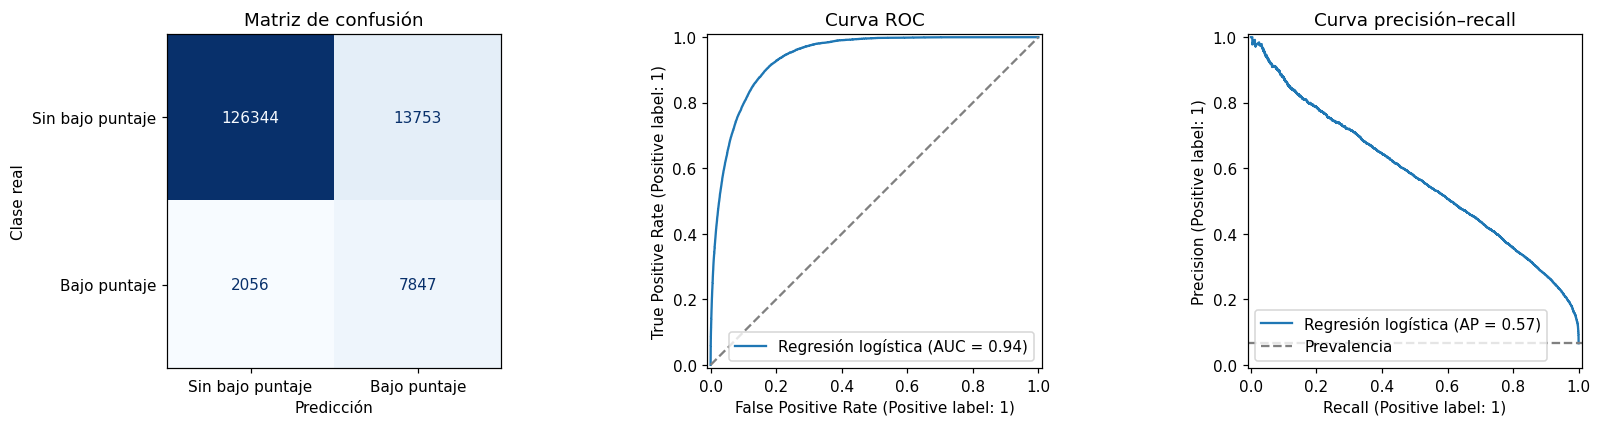

In [9]:
X_test=validar_entradas(test);y_test=objetivo(test)
filas=[];pt={}
for nombre,m in modelos.items():
    pt[nombre]=m.predict_proba(X_test)[:,1]
    filas.append({'Modelo':nombre,'Umbral':umbrales[nombre],**medir(y_test,pt[nombre],umbrales[nombre])})
resultados=pd.DataFrame(filas).set_index('Modelo');resultados.to_csv(OUT/'metricas_test.csv')
print(resultados.round(4).to_string())
p=pt[elegido];pred=(p>=umbral).astype(int);cm=confusion_matrix(y_test,pred,labels=[0,1])
tn,fp,fn,tp=cm.ravel()
fig,ax=plt.subplots(1,3,figsize=(16,4))
ConfusionMatrixDisplay(cm,display_labels=['Sin bajo puntaje','Bajo puntaje']).plot(ax=ax[0],colorbar=False,cmap='Blues',values_format='d')
ax[0].set_title('Matriz de confusión');ax[0].set_xlabel('Predicción');ax[0].set_ylabel('Clase real')
RocCurveDisplay.from_predictions(y_test,p,ax=ax[1],name=elegido);ax[1].plot([0,1],[0,1],'--',color='gray');ax[1].set_title('Curva ROC')
PrecisionRecallDisplay.from_predictions(y_test,p,ax=ax[2],name=elegido);ax[2].axhline(y_test.mean(),ls='--',color='gray',label='Prevalencia');ax[2].legend();ax[2].set_title('Curva precisión–recall')
plt.tight_layout();plt.savefig(OUT/'evaluacion_test.png',dpi=140);plt.show()
r=resultados.loc[elegido]
print(f'Modelo seleccionado: {elegido}. Recall {r.Recall:.1%}; precisión {r.Precision:.1%}; F2 {r.F2:.3f}.')
print(f'Detecta {tp:,} casos positivos; omite {fn:,}; genera {fp:,} falsas alertas y {tn:,} negativos correctos.')
print(f'Se revisarían {int(pred.sum()):,} de {len(test):,} registros ({pred.mean():.1%}).')
print('La referencia mayoritaria no identifica positivos aunque su exactitud pueda parecer alta.')

### Lectura de los resultados de esta ejecución
El modelo elegido en validación fue **Regresión logística**, con umbral de probabilidad **0.12**. En la muestra de test obtuvo recall de **79.2%**, precisión de **36.3%** y F2 de **0.641**.

Identificó **7,847** casos de bajo puntaje, dejó sin detectar **2,056** y generó **13,753** falsas alertas. Por ello, el uso de una señal debe acompañarse de revisión humana y de una evaluación de la capacidad de atención. Estos números cambian si se modifica el corte, la muestra o el modelo; al volver a ejecutar con otra configuración, actualizar esta interpretación con la salida del paso 6.

La auditoría presenta brechas descriptivas entre subgrupos con tamaños e intervalos de confianza. No basta una brecha pequeña para afirmar equidad, especialmente porque los datos son sintéticos.

Los F2 de validación de regresión logística (0,6473) e HistGradientBoosting (0,6470) son muy próximos. Se aplica la regla de selección prevista, sin afirmar una superioridad estadística entre ellos.

### Auditoría de equidad correspondiente a RF-03
Se conserva género, etnia y nivel socioeconómico únicamente en una tabla de auditoría. Se calculan tamaños, casos positivos, recall, precisión y tasa de falsos positivos por subgrupo. Las métricas sin denominador se expresan como NaN, no como cero.

Se incorpora un intervalo de Wilson del 95 % para recall para mostrar incertidumbre de muestreo. Las brechas máximas son descriptivas; no constituyen prueba de discriminación ni certificación de equidad. No se eligen umbrales diferentes por atributo protegido. Esta auditoría sobre datos sintéticos debe repetirse con datos institucionales autorizados antes de cualquier uso real.

In [10]:
def wilson(aciertos,n,z=1.96):
    if n==0:return (np.nan,np.nan)
    p=aciertos/n;den=1+z*z/n;centro=(p+z*z/(2*n))/den
    margen=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
    return centro-margen,centro+margen
audit=test[AUDITORIA].copy();audit['real']=y_test.to_numpy();audit['pred']=pred
filas=[]
for atributo in AUDITORIA:
    for grupo,g in audit.groupby(atributo,dropna=False):
        tn_g,fp_g,fn_g,tp_g=confusion_matrix(g.real,g.pred,labels=[0,1]).ravel()
        pos=tp_g+fn_g;neg=tn_g+fp_g;lo,hi=wilson(tp_g,pos)
        filas.append({'Atributo':atributo,'Grupo':str(grupo),'N':len(g),'Positivos':int(pos),
          'Recall':tp_g/pos if pos else np.nan,'Recall_IC95_inf':lo,'Recall_IC95_sup':hi,
          'FPR':fp_g/neg if neg else np.nan,'Precision':tp_g/(tp_g+fp_g) if tp_g+fp_g else np.nan,
          'Tasa_alertas':g.pred.mean()})
equidad=pd.DataFrame(filas);equidad.to_csv(OUT/'auditoria_equidad_restringida.csv',index=False)
print(equidad.round(4).to_string(index=False))
brechas=equidad.groupby('Atributo')[['Recall','FPR']].agg(lambda s:s.max()-s.min())
print('\nBrechas max–min por atributo (proporciones):\n',brechas.round(4).to_string())
print('El nombre restringida indica el destino previsto, no aplica permisos ni cifrado por sí solo.')

    Atributo       Grupo     N  Positivos  Recall  Recall_IC95_inf  Recall_IC95_sup    FPR  Precision  Tasa_alertas
      Gender      Female 76497       5020  0.7922           0.7808           0.8032 0.0973     0.3638        0.1429
      Gender        Male 73503       4883  0.7925           0.7809           0.8037 0.0991     0.3628        0.1451
        Race       Asian  7483        474  0.7911           0.7523           0.8253 0.0972     0.3551        0.1411
        Race       Black 22681       1480  0.7912           0.7698           0.8112 0.0985     0.3593        0.1437
        Race    Hispanic 43546       2949  0.7864           0.7712           0.8008 0.0963     0.3722        0.1431
        Race       Other  3041        213  0.8310           0.7749           0.8753 0.0916     0.4060        0.1434
        Race Two-or-more  7434        493  0.8053           0.7680           0.8378 0.1046     0.3535        0.1511
        Race       White 65815       4294  0.7937           0.7813      

### ¿La preparación fue suficiente para el proyecto?
Sí permitió ejecutar un prototipo coherente con matemáticas, controlar las particiones y medir errores y diferencias entre subgrupos. No es suficiente para declarar cumplidos los hitos H4–H7: faltan aprobación de UTP y comité, definición del corte, disponibilidad temporal de entradas, validación institucional, seguridad, dashboard y piloto.

Tampoco se debe trasladar el porcentaje de aciertos a una promesa de beneficio pedagógico. La adopción de al menos 70 % de docentes del primer semestre que aparece en la evaluación 2 es un indicador de uso del piloto, no una métrica de precisión del modelo.

## 7 Utilizar el modelo con cinco nuevos datos
Los cinco perfiles son ficticios, construidos para demostrar inferencia. No se extraen de train ni test y no tienen puntaje real asignado: no permiten calcular exactitud. Se entregan probabilidades estimadas sin calibración adicional.

Se definen dos niveles operativos provisionales: **priorizar revisión** si supera el umbral seleccionado, y **seguimiento habitual** en otro caso. No se inventa un tercer nivel sin acordar su utilidad y sus límites. Ambos requieren interpretación docente; una ausencia de alerta no garantiza ausencia de dificultades.

In [11]:
nuevos=pd.DataFrame([
 [10,0.73,0.3,0,0,1,0,4,4],
 [11,0.82,0.6,1,0,1,0,3,3],
 [12,0.90,1.0,1,1,0,1,3,2],
 [10,0.97,1.7,1,1,0,1,2,1],
 [9,0.78,0.4,1,0,0,0,4,4]],columns=FEATURES)
nuevos.insert(0,'ID_Caso',[f'DEMO_{i}' for i in range(1,6)])
prob_nuevos=final.predict_proba(validar_entradas(nuevos))[:,1]
cinco=pd.DataFrame({'ID_Caso':nuevos.ID_Caso,'Probabilidad_bajo_rendimiento':prob_nuevos,
 'Alerta':(prob_nuevos>=umbral).astype(int),
 'Nivel':np.where(prob_nuevos>=umbral,'Priorizar revisión','Seguimiento habitual')})
print(cinco.round(4).to_string(index=False))
nuevos.to_csv(OUT/'cinco_casos_nuevos.csv',index=False);cinco.to_csv(OUT/'cinco_predicciones.csv',index=False)

ID_Caso  Probabilidad_bajo_rendimiento  Alerta                Nivel
 DEMO_1                         0.9905       1   Priorizar revisión
 DEMO_2                         0.4206       1   Priorizar revisión
 DEMO_3                         0.0073       0 Seguimiento habitual
 DEMO_4                         0.0001       0 Seguimiento habitual
 DEMO_5                         0.8726       1   Priorizar revisión


## 8 Proponer e implementar una automatización
**Propuesta alineada con la evaluación 2:** actualizar predicciones por lotes al menos semestralmente. Un lote autorizado produce un CSV para el dashboard docente, una bitácora y un resumen técnico. Se evita enviar mensajes o tomar decisiones académicas automáticamente.

**Implementación de este cuaderno:** guarda el pipeline completo y su configuración; vuelve a cargarlo; verifica entradas; genera predicciones; registra tamaño, duración, faltantes imputados, tasa de alertas, huella de entrada y versión. Cada salida usa un nombre único para no sobreescribir ejecuciones.

RF-04 (historial individual) y RF-05 (alerta por aumento de riesgo entre periodos) requieren identificadores estables y mediciones temporales reales, que el dataset no incluye. Se registra historial de ejecuciones; no se finge disponer de historia longitudinal. La programación semestral en un servicio persistente, accesos por rol, cifrado y auditoría de accesos quedan pendientes. Colab no garantiza ejecución programada con la sesión cerrada.

In [12]:
paquete={'pipeline':final,'features':FEATURES,'nombre_modelo':elegido,'umbral':umbral,
 'corte_math':CORTE_MATH,'version':'matematicas_v2','dataset':HANDLE,'sklearn':sklearn.__version__}
joblib.dump(paquete,OUT/'modelo_matematicas.joblib')
# Cargar solo archivos joblib propios o de una fuente de confianza.
def procesar_lote(ruta_csv,ruta_modelo=OUT/'modelo_matematicas.joblib',destino=OUT/'lotes'):
    inicio=time.perf_counter();destino=Path(destino);destino.mkdir(parents=True,exist_ok=True)
    m=joblib.load(ruta_modelo)
    if m['sklearn']!=sklearn.__version__:raise ValueError('Usar la versión de sklearn registrada al entrenar.')
    if m['features']!=FEATURES:raise ValueError('Contrato de variables incompatible.')
    datos=pd.read_csv(ruta_csv);x=validar_entradas(datos)
    if 'ID_Caso' not in datos:raise ValueError('El lote debe incluir ID_Caso seudónimo.')
    if datos.ID_Caso.isna().any() or datos.ID_Caso.duplicated().any():raise ValueError('ID_Caso debe ser único y no nulo en el lote.')
    p=m['pipeline'].predict_proba(x)[:,1];alerta=(p>=m['umbral']).astype(int)
    ahora=datetime.now(timezone.utc);sello=ahora.strftime('%Y%m%dT%H%M%S%fZ')
    salida=pd.DataFrame({'ID_Caso':datos.ID_Caso,'Probabilidad_bajo_rendimiento':p,'Alerta':alerta,
      'Nivel':np.where(alerta==1,'Priorizar revisión','Seguimiento habitual'),
      'Fecha_UTC':ahora.isoformat(),'Version_modelo':m['version']})
    ruta=destino/f'predicciones_powerbi_{sello}.csv';salida.to_csv(ruta,index=False)
    resumen={'Fecha_UTC':ahora.isoformat(),'Version':m['version'],'Modelo':m['nombre_modelo'],
      'Filas':len(datos),'Alertas':int(alerta.sum()),'Tasa_alertas':float(alerta.mean()),
      'Valores_imputados':int(x.isna().sum().sum()),'SHA256_entrada':sha256_archivo(ruta_csv),
      'Umbral':m['umbral'],'Duracion_segundos':round(time.perf_counter()-inicio,3),'Archivo':ruta.name}
    (destino/f'resumen_{sello}.json').write_text(json.dumps(resumen,ensure_ascii=False,indent=2),encoding='utf-8')
    historial=destino/'historial_ejecuciones.csv'
    pd.DataFrame([resumen]).to_csv(historial,mode='a',header=not historial.exists(),index=False)
    return salida,resumen
salida_lote,resumen_lote=procesar_lote(OUT/'cinco_casos_nuevos.csv')
assert np.allclose(salida_lote.Probabilidad_bajo_rendimiento,cinco.Probabilidad_bajo_rendimiento)
assert list(salida_lote.Alerta)==list(cinco.Alerta)
# Comprobación del rechazo de entradas inválidas.
invalido=nuevos.copy();invalido.loc[0,'AttendanceRate']=90
try:
    validar_entradas(invalido)
except ValueError as error:
    print('Control de escala verificado:',error)
else:
    raise AssertionError('El control debía rechazar asistencia 90 en escala 0–1.')
print(salida_lote.to_string(index=False));print(json.dumps(resumen_lote,ensure_ascii=False,indent=2))

Control de escala verificado: AttendanceRate fuera de rango 0.7–1.
ID_Caso  Probabilidad_bajo_rendimiento  Alerta                Nivel                        Fecha_UTC Version_modelo
 DEMO_1                       0.990533       1   Priorizar revisión 2026-10-25T02:23:58.080196+00:00 matematicas_v2
 DEMO_2                       0.420572       1   Priorizar revisión 2026-10-25T02:23:58.080196+00:00 matematicas_v2
 DEMO_3                       0.007300       0 Seguimiento habitual 2026-10-25T02:23:58.080196+00:00 matematicas_v2
 DEMO_4                       0.000103       0 Seguimiento habitual 2026-10-25T02:23:58.080196+00:00 matematicas_v2
 DEMO_5                       0.872634       1   Priorizar revisión 2026-10-25T02:23:58.080196+00:00 matematicas_v2
{
  "Fecha_UTC": "2026-10-25T02:23:58.080196+00:00",
  "Version": "matematicas_v2",
  "Modelo": "Regresión logística",
  "Filas": 5,
  "Alertas": 3,
  "Tasa_alertas": 0.6,
  "Valores_imputados": 0,
  "SHA256_entrada": "8e1fab6f17ad2014da

### Trazabilidad y ficha del modelo
Se exporta una ficha con objetivo, configuración, procedencia, métricas, limitaciones y alcance. Los archivos permiten versionar posteriormente el trabajo en Git, pero no se crea un repositorio ni se afirma que se haya hecho un commit.

Para Power BI: importar `predicciones_powerbi_*.csv`, establecer la probabilidad como decimal y usar ID_Caso, Nivel y Fecha_UTC. La tabla de auditoría por atributos protegidos se reserva al comité/DPO; no debe mezclarse con el listado docente. Aquí se separan archivos, pero un entorno real debe hacer cumplir los permisos.

In [13]:
ficha={'nombre':'Clasificación de bajo puntaje en matemáticas','version':paquete['version'],
 'datos_sinteticos':True,'dataset':HANDLE,'corte_provisional':CORTE_MATH,'features':FEATURES,
 'atributos_solo_auditoria':AUDITORIA,'modelo':elegido,'umbral_validacion':umbral,
 'muestreo':TAMANOS,'semilla':SEED,'calidad_archivos':calidad,'versiones_software':versiones,
 'metricas_test':resultados.loc[elegido].to_dict(),
 'limitaciones':['Corte no aprobado por UTP','Datos sin secuencia temporal ni ID de estudiante',
 'Test explorado previamente','Métricas calculadas en muestras','Probabilidades sin calibración adicional',
 'No acredita desempeño ni equidad en un colegio real','Seguridad y programación de producción pendientes']}
(OUT/'ficha_modelo.json').write_text(json.dumps(ficha,indent=2,ensure_ascii=False),encoding='utf-8')
(OUT/'versiones_entorno.json').write_text(json.dumps(versiones,indent=2),encoding='utf-8')
print('Archivos generados:')
for archivo in sorted(OUT.rglob('*')):
    if archivo.is_file():print(archivo.relative_to(OUT))

Archivos generados:
auditoria_equidad_restringida.csv
busqueda_umbrales.csv
calidad_y_procedencia.csv
cinco_casos_nuevos.csv
cinco_predicciones.csv
clases_train.png
evaluacion_test.png
ficha_modelo.json
importancia_variables.csv
importancias.png
lotes/historial_ejecuciones.csv
lotes/predicciones_powerbi_20261025T022358080196Z.csv
lotes/resumen_20261025T022358080196Z.json
metricas_test.csv
metricas_validacion.csv
modelo_matematicas.joblib
versiones_entorno.json


### Seguimiento del proyecto y controles pendientes
| Actividad de la evaluación 2 | Evidencia de esta actividad | Estado |
|---|---|---|
| 02 Acordar objetivo métricas y umbrales | Objetivo matemáticas, F2 y corte provisional documentados | Propuesta; falta aprobación |
| 08 a 11 Calidad preparación y separación | Controles completos de archivos y pipeline reproducible | Prototipo ejecutado |
| 12 y 13 Entrenamiento y ajuste | Referencia, dos candidatos y búsqueda en validación | Ejecutado |
| 15 Evaluación por subgrupo | Métricas y exportación de equidad | Ejecutado sobre datos sintéticos |
| 16 H4 Revisión del comité | Ficha y resultados disponibles | Pendiente de aprobación |
| 18 y 19 Dashboard e integración por lotes | Exportación para Power BI y función de inferencia | Parcial; sin dashboard ni accesos por rol |
| 20 H5 Seguridad y recuperación | No se simulan aprobaciones ni cifrado institucional | Pendiente |
| 24 a 26 Piloto aceptación y operación | No realizado por este notebook | Pendiente |

Esto puede registrarse como evidencia en Jira/Trello; no se han creado tarjetas externas. El calendario de 26 semanas y el presupuesto de las evaluaciones se mantienen como plan, sin atribuir costos ficticios a esta ejecución.

**Monitoreo propuesto, coherente con el plan:** revisión semanal de lotes e incidencias por DE; revisión mensual de desempeño cuando existan etiquetas, deriva y equidad por DS/JP; revisión trimestral de riesgos por JP/DPO; actualización al menos semestral y auditoría antes de desplegar o reentrenar. La tasa de alertas o los faltantes pueden señalar un cambio de datos, pero por sí solos no demuestran deterioro predictivo.

## Reflexión grupal
**¿Qué componente tendrá mayor impacto en el éxito del negocio: el modelo, la automatización o la forma de comunicar los resultados? ¿Por qué?**

Como grupo, consideramos que la comunicación de los resultados tendría el mayor impacto. El proyecto busca que los docentes puedan identificar a quién conviene ofrecer apoyo en matemáticas. Un modelo con buenas métricas no cumpliría ese propósito si el docente no entiende una alerta o la interpreta como una etiqueta definitiva del estudiante.

Por eso, explicaríamos el nivel de revisión, la incertidumbre y los errores del modelo con un lenguaje sencillo. La automatización permitiría actualizar la información sin repetir todo manualmente y el modelo ayudaría a priorizar los casos. Sin embargo, la decisión debe quedar en manos del equipo docente, considerando el contexto del estudiante. Esta elección también se relaciona con la meta del proyecto: lograr que al menos el 70 % de los docentes use regularmente el dashboard durante el primer semestre, indicador que solo podrá comprobarse en el piloto.

## Conclusión
Se implementó el flujo técnico del proyecto con el objetivo correcto de matemáticas, usando muestras independientes de los tres archivos originales. Se documentó un criterio provisional de bajo rendimiento, se separó el ajuste de la evaluación y se incorporó una auditoría de equidad y una automatización demostrable.

Las métricas obtenidas describen este experimento sintético y el corte elegido. La preparación permite continuar con la revisión del docente y los responsables del proyecto; no permite declarar listo un sistema de alerta temprana institucional. El siguiente paso es acordar el corte y las entradas disponibles antes de la predicción, y luego validar el modelo con datos institucionales autorizados y temporalmente separados.